<a href="https://colab.research.google.com/github/lorna-nyabuto/BIOINFORMATICSPROJECT/blob/main/TB_host_response.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Stage 1: Question and Objectives

## Research Question
Can whole-blood gene expression tell active TB apart from latent TB infection in African adults, and does this still work in people living with HIV?

## Hypothesis
Active TB causes an interferon-driven change in blood gene expression that separates it from latent TB. HIV co-infection blurs that difference, so classifiers will perform worse in HIV+ patients.

## Objectives
1. Find genes that are expressed differently in active TB and latent TB, using FDR correction.
2. Run GO and pathway enrichment on those genes to check whether interferon and immune pathways come out on top.
3. Train a classifier for active vs. latent TB and compare it with two baselines: a majority-class model and the published 3-gene Sweeney score (GBP5, DUSP3, KLF2).
4. Compare how well the model performs in HIV-negative and HIV-positive patients.

# Stage 2: Data Acquisition

In [1]:
import os, gzip
import pandas as pd

os.makedirs("data", exist_ok=True)
!wget -q -P data https://ftp.ncbi.nlm.nih.gov/geo/series/GSE37nnn/GSE37250/matrix/GSE37250_series_matrix.txt.gz
!ls -lh data

total 557M
-rw-r--r-- 1 root root 666K Nov 16 19:54 de_active_vs_latent.csv
-rw-r--r-- 1 root root  14M Nov 16 19:54 expr_gene.pkl
-rw-r--r-- 1 root root  23M Nov 16 19:54 expr_log.pkl
-rw-r--r-- 1 root root 7.0M Aug 22  2016 GPL10558.annot.gz
-rw-r--r-- 1 root root 7.0M Aug 22  2016 GPL10558.annot.gz.1
-rw-r--r-- 1 root root 102M Sep  1 07:03 GSE37250_series_matrix.txt.gz
-rw-r--r-- 1 root root 102M Sep  1 07:03 GSE37250_series_matrix.txt.gz.1
-rw-r--r-- 1 root root 102M Sep  1 07:03 GSE37250_series_matrix.txt.gz.2
-rw-r--r-- 1 root root 102M Sep  1 07:03 GSE37250_series_matrix.txt.gz.3
-rw-r--r-- 1 root root 102M Sep  1 07:03 GSE37250_series_matrix.txt.gz.4
-rw-r--r-- 1 root root  51K Nov 16 19:54 meta_al.pkl


In [2]:
path = "data/GSE37250_series_matrix.txt.gz"

expr = pd.read_csv(path, sep="\t", comment="!", index_col=0, compression="gzip")
expr = expr.astype("float32")   # halves the memory use

print("Expression matrix shape (probes, samples):", expr.shape)
expr.iloc[:5, :5]

Expression matrix shape (probes, samples): (47323, 537)


,GSM914353,GSM914354,GSM914355,GSM914356,GSM914357
ID_REF,,,,,
ILMN_1343291,44761.148438,46525.449219,49341.351562,46176.179688,43302.750000
ILMN_1343295,10601.830078,12156.830078,13789.980469,13414.110352,11459.809570
ILMN_1651199,-18.379730,-22.095310,12.490730,15.022080,8.897725
ILMN_1651209,46.603321,34.430611,47.021049,49.063030,39.318359
ILMN_1651210,2.132195,-6.597260,3.118381,17.818670,23.502970


In [3]:
rows = []
with gzip.open(path, "rt") as f:
    for line in f:
        if line.startswith("!Sample_"):
            parts = line.rstrip("\n").split("\t")
            rows.append((parts[0], [p.strip('"') for p in parts[1:]]))
        elif line.startswith("!series_matrix_table_begin"):
            break

meta = {}
for key, vals in rows:
    if key == "!Sample_characteristics_ch1":
        name = vals[0].split(":")[0].strip()
        vals = [v.split(":", 1)[1].strip() if ":" in v else v for v in vals]
        meta[name] = vals
    elif key in ("!Sample_geo_accession", "!Sample_title"):
        meta[key.replace("!Sample_", "")] = vals

meta = pd.DataFrame(meta).set_index("geo_accession")
print("Metadata shape:", meta.shape)
print(meta.columns.tolist())
meta.head(3).T

Metadata shape: (537, 5)
['title', 'disease state', 'hiv status', 'geographical region', 'tissue']


geo_accession,GSM914353,GSM914354,GSM914355
title,active tuberculosis HIV negative Malawi WB_1_M...,active tuberculosis HIV negative Malawi WB_1_M...,active tuberculosis HIV negative Malawi WB_1_M...
disease state,active tuberculosis,active tuberculosis,active tuberculosis
hiv status,HIV negative,HIV negative,HIV negative
geographical region,Malawi,Malawi,Malawi
tissue,whole blood,whole blood,whole blood


In [4]:
!rm -f data/GSE37250_family.soft.gz
!ls -lh data

total 557M
-rw-r--r-- 1 root root 666K Nov 16 19:54 de_active_vs_latent.csv
-rw-r--r-- 1 root root  14M Nov 16 19:54 expr_gene.pkl
-rw-r--r-- 1 root root  23M Nov 16 19:54 expr_log.pkl
-rw-r--r-- 1 root root 7.0M Aug 22  2016 GPL10558.annot.gz
-rw-r--r-- 1 root root 7.0M Aug 22  2016 GPL10558.annot.gz.1
-rw-r--r-- 1 root root 102M Sep  1 07:03 GSE37250_series_matrix.txt.gz
-rw-r--r-- 1 root root 102M Sep  1 07:03 GSE37250_series_matrix.txt.gz.1
-rw-r--r-- 1 root root 102M Sep  1 07:03 GSE37250_series_matrix.txt.gz.2
-rw-r--r-- 1 root root 102M Sep  1 07:03 GSE37250_series_matrix.txt.gz.3
-rw-r--r-- 1 root root 102M Sep  1 07:03 GSE37250_series_matrix.txt.gz.4
-rw-r--r-- 1 root root  51K Nov 16 19:54 meta_al.pkl


In [5]:
print(expr.shape, meta.shape)
print("Sample IDs match, same order:", list(expr.columns) == list(meta.index))
print("Missing values in expression:", expr.isna().sum().sum())
print("Missing values in metadata:", meta.isna().sum().sum())
print()
print(meta["disease state"].value_counts(), "\n")
print(meta["hiv status"].value_counts(), "\n")
print(meta["geographical region"].value_counts(), "\n")
pd.crosstab(meta["disease state"], [meta["geographical region"], meta["hiv status"]])

(47323, 537) (537, 5)
Sample IDs match, same order: True
Missing values in expression: 0
Missing values in metadata: 0

disease state
active tuberculosis    195
other disease          175
latent TB infection    167
Name: count, dtype: int64 

hiv status
HIV positive    274
HIV negative    263
Name: count, dtype: int64 

geographical region
South Africa    300
Malawi          237
Name: count, dtype: int64 



geographical region       Malawi              South Africa             
hiv status          HIV negative HIV positive HIV negative HIV positive
disease state                                                          
active tuberculosis           51           51           46           47
latent TB infection           35           36           48           48
other disease                 34           30           49           62

## Data description

**Source:** GEO accession GSE37250 (Kaforou et al., 2013), downloaded as `GSE37250_series_matrix.txt.gz` from NCBI GEO.

**Expression matrix (`expr`):** rows are microarray probes (Illumina ILMN_ IDs), columns are samples (GSM IDs). Values are gene expression intensities, shape 47,323 probes x 537 samples.

**Metadata (`meta`):** one row per sample, with these variables:
- `title`: sample label (disease, HIV status, country, sample code)
- `disease state`: active TB, latent TB, or other disease
- `hiv status`: HIV negative or HIV positive
- `geographical region`: South Africa or Malawi
- `tissue`: whole blood for all samples

**Sample counts:** 537 samples in total. Disease state: 195 active TB, 167 latent TB infection, 175 other disease. HIV status: 274 positive, 263 negative. Region: 300 South Africa, 237 Malawi. There are no missing values in the expression matrix or the metadata, and sample IDs match between the two tables. For the main analysis we use only the active TB and latent TB samples (n = 362).

# Stage 3: Preprocessing and Quality Control

In [6]:
import numpy as np
import matplotlib.pyplot as plt

print("BEFORE: samples =", expr.shape[1], "| probes =", expr.shape[0])

keep = meta["disease state"].isin(["active tuberculosis", "latent TB infection"])
meta_al = meta[keep].copy()
expr_al = expr.loc[:, meta_al.index].copy()
meta_al["label"] = (meta_al["disease state"] == "active tuberculosis").astype(int)  # 1 = active, 0 = latent

print("AFTER removing 'other disease': samples =", expr_al.shape[1], "| probes =", expr_al.shape[0])
print(meta_al["disease state"].value_counts())

BEFORE: samples = 537 | probes = 47323
AFTER removing 'other disease': samples = 362 | probes = 47323
disease state
active tuberculosis    195
latent TB infection    167
Name: count, dtype: int64


In [7]:
n_before = expr_al.shape[0]

threshold = 64        # raw intensity cutoff
min_samples = 167     # size of the smallest group (latent TB)

detected = (expr_al > threshold).sum(axis=1) >= min_samples
expr_f = expr_al.loc[detected].copy()

print("BEFORE probe filter:", n_before, "probes")
print("AFTER probe filter: ", expr_f.shape[0], "probes")
print("Removed:", n_before - expr_f.shape[0], f"({(1 - expr_f.shape[0]/n_before)*100:.1f}%)")
print("Negative values remaining:", f"{(expr_f.values < 0).mean()*100:.2f}%")

for thr in [32, 64, 128]:
    kept = ((expr_al > thr).sum(axis=1) >= min_samples).sum()
    print(f"threshold {thr}: {kept} probes kept")

BEFORE probe filter: 47323 probes
AFTER probe filter:  16000 probes
Removed: 31323 (66.2%)
Negative values remaining: 0.33%
threshold 32: 21574 probes kept
threshold 64: 16000 probes kept
threshold 128: 12335 probes kept


Values below 1 (will be set to 1 before log2): 20780
Shape: (16000, 362)
Range: 0.0 to 15.82


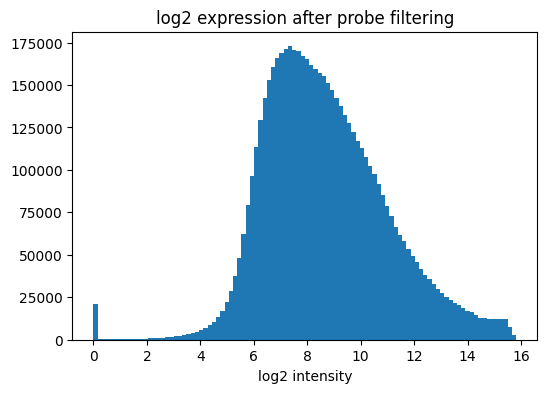

In [8]:
n_below_1 = (expr_f.values < 1).sum()
print("Values below 1 (will be set to 1 before log2):", n_below_1)

expr_log = np.log2(expr_f.clip(lower=1))

print("Shape:", expr_log.shape)
print("Range:", round(float(expr_log.values.min()), 2), "to", round(float(expr_log.values.max()), 2))

plt.figure(figsize=(6, 4))
plt.hist(expr_log.values.flatten(), bins=100)
plt.title("log2 expression after probe filtering"); plt.xlabel("log2 intensity")
plt.show()

In [9]:
print("Duplicate probe IDs:", expr_log.index.duplicated().sum())
print("Duplicate samples (identical columns):", expr_log.T.duplicated().sum())
print("Samples and metadata aligned:", list(expr_log.columns) == list(meta_al.index))

Duplicate probe IDs: 0
Duplicate samples (identical columns): 0
Samples and metadata aligned: True


In [10]:
import os, gzip
from io import StringIO

if not os.path.exists("data/GPL10558.annot.gz"):
    !wget -q -P data https://ftp.ncbi.nlm.nih.gov/geo/platforms/GPL10nnn/GPL10558/annot/GPL10558.annot.gz

with gzip.open("data/GPL10558.annot.gz", "rt") as f:
    lines = f.readlines()
start = next(i for i, l in enumerate(lines) if l.startswith("!platform_table_begin")) + 1
end = next(i for i, l in enumerate(lines) if l.startswith("!platform_table_end"))
ann = pd.read_csv(StringIO("".join(lines[start:end])), sep="\t", low_memory=False)
print("Annotation shape:", ann.shape)

Annotation shape: (48107, 22)


In [11]:
probe_to_gene = ann.set_index("ID")["Gene symbol"].reindex(expr_log.index)
print("Filtered probes with a gene symbol:", probe_to_gene.notna().sum(), "of", len(probe_to_gene))

has_sym = probe_to_gene.dropna()
print("Probes mapping to several genes ('///'):", has_sym.str.contains("///").sum())
has_sym = has_sym[~has_sym.str.contains("///")]

tmp = expr_log.loc[has_sym.index].copy()
tmp["mean_expr"] = tmp.mean(axis=1)
tmp["gene"] = has_sym
expr_g = (tmp.sort_values("mean_expr", ascending=False)
             .drop_duplicates("gene")
             .set_index("gene")
             .drop(columns="mean_expr"))

print("Probes kept:", len(has_sym))
print("Gene-level matrix (genes, samples):", expr_g.shape)

Filtered probes with a gene symbol: 12931 of 16000
Probes mapping to several genes ('///'): 3
Probes kept: 12928
Gene-level matrix (genes, samples): (10065, 362)


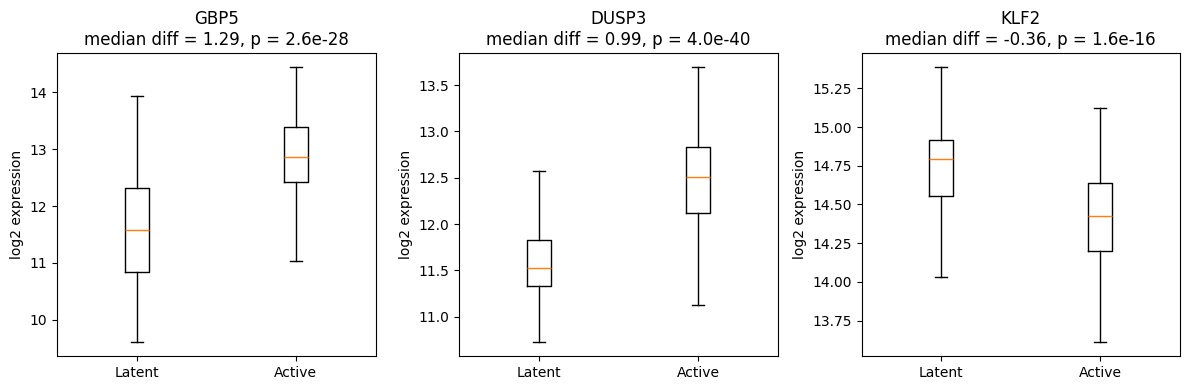

In [12]:
from scipy.stats import mannwhitneyu

active_ids = meta_al.index[meta_al["label"] == 1]
latent_ids = meta_al.index[meta_al["label"] == 0]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, g in zip(axes, ["GBP5", "DUSP3", "KLF2"]):
    a = expr_g.loc[g, active_ids]
    l = expr_g.loc[g, latent_ids]
    p = mannwhitneyu(a, l).pvalue
    ax.boxplot([l, a], showfliers=False)
    ax.set_xticks([1, 2]); ax.set_xticklabels(["Latent", "Active"])
    ax.set_title(f"{g}\nmedian diff = {a.median() - l.median():.2f}, p = {p:.1e}")
    ax.set_ylabel("log2 expression")
plt.tight_layout(); plt.show()

In [13]:
for thr in [32, 64, 128]:
    kept = ((expr_al > thr).sum(axis=1) >= 167).sum()
    print(f"threshold {thr}: {kept} probes kept")

threshold 32: 21574 probes kept
threshold 64: 16000 probes kept
threshold 128: 12335 probes kept


### QC summary
- **Samples:** 537 → 362 after removing the 175 "other disease" samples (195 active TB, 167 latent TB kept).
- **Probes:** 47,323 → 16,000 after removing probes not detected (raw intensity > 64 in at least 167 samples, the size of the smallest group). 31,323 probes (66.2%) were removed.
- **Raw values:** intensities are background-subtracted Illumina values, so 29.1% of raw values were negative. These are probes with signal below the background estimate, not real negative expression. After filtering only 0.33% remained negative.
- **Transformation:** values below 1 (20,780 values, about 0.36%) were set to 1, then log2-transformed. This creates a small spike at 0 in the histogram.
- **Between-sample normalisation:** the GEO processing notes state the data were background-subtracted and quantile normalised in GenomeStudio. This matches what we saw (per-sample medians 4.64 to 4.67, identical boxplots), so no further normalisation was applied.
- **Integrity:** no duplicate probes or samples; expression and metadata are aligned.

- **Sensitivity of the probe filter:** with thresholds of 32, 64 and 128 (same 167-sample rule), 21,574, 16,000 and 12,335 probes were kept respectively. The count changes smoothly, so the results are not sensitive to one arbitrary cutoff. We used 64.

In [14]:
expr_log.to_pickle("data/expr_log.pkl")
meta_al.to_pickle("data/meta_al.pkl")
print("saved")

saved


In [15]:
with gzip.open("data/GSE37250_series_matrix.txt.gz", "rt") as f:
    for line in f:
        if line.startswith("!Series_platform_id") or line.startswith("!Sample_data_processing"):
            print(line[:400])
            break

!Series_platform_id	"GPL10558"



In [16]:
with gzip.open("data/GSE37250_series_matrix.txt.gz", "rt") as f:
    for line in f:
        if line.startswith("!Sample_data_processing"):
            print(line[:600])
            break

!Sample_data_processing	"The data were normalised using Genome Studio, with background subtracted and quantile normalised."	"The data were normalised using Genome Studio, with background subtracted and quantile normalised."	"The data were normalised using Genome Studio, with background subtracted and quantile normalised."	"The data were normalised using Genome Studio, with background subtracted and quantile normalised."	"The data were normalised using Genome Studio, with background subtracted and quantile normalised."	"The data were normalised using Genome Studio, with background subtracted an


In [17]:
!wget -q -P data https://ftp.ncbi.nlm.nih.gov/geo/platforms/GPL10nnn/GPL10558/annot/GPL10558.annot.gz
!ls -lh data

total 564M
-rw-r--r-- 1 root root 666K Nov 16 19:54 de_active_vs_latent.csv
-rw-r--r-- 1 root root  14M Nov 16 19:54 expr_gene.pkl
-rw-r--r-- 1 root root  23M Nov 16 20:01 expr_log.pkl
-rw-r--r-- 1 root root 7.0M Aug 22  2016 GPL10558.annot.gz
-rw-r--r-- 1 root root 7.0M Aug 22  2016 GPL10558.annot.gz.1
-rw-r--r-- 1 root root 7.0M Aug 22  2016 GPL10558.annot.gz.2
-rw-r--r-- 1 root root 102M Sep  1 07:03 GSE37250_series_matrix.txt.gz
-rw-r--r-- 1 root root 102M Sep  1 07:03 GSE37250_series_matrix.txt.gz.1
-rw-r--r-- 1 root root 102M Sep  1 07:03 GSE37250_series_matrix.txt.gz.2
-rw-r--r-- 1 root root 102M Sep  1 07:03 GSE37250_series_matrix.txt.gz.3
-rw-r--r-- 1 root root 102M Sep  1 07:03 GSE37250_series_matrix.txt.gz.4
-rw-r--r-- 1 root root  51K Nov 16 20:01 meta_al.pkl


In [18]:
ann_path = "data/GPL10558.annot.gz"

with gzip.open(ann_path, "rt") as f:
    lines = f.readlines()

start = next(i for i, l in enumerate(lines) if l.startswith("!platform_table_begin")) + 1
end = next(i for i, l in enumerate(lines) if l.startswith("!platform_table_end"))

from io import StringIO
ann = pd.read_csv(StringIO("".join(lines[start:end])), sep="\t", low_memory=False)

print("Annotation shape:", ann.shape)
print(ann.columns.tolist())
ann.iloc[:3, :8]

Annotation shape: (48107, 22)
['ID', 'Gene title', 'Gene symbol', 'Gene ID', 'UniGene title', 'UniGene symbol', 'UniGene ID', 'Nucleotide Title', 'GI', 'GenBank Accession', 'Platform_CLONEID', 'Platform_ORF', 'Platform_SPOTID', 'Chromosome location', 'Chromosome annotation', 'GO:Function', 'GO:Process', 'GO:Component', 'GO:Function ID', 'GO:Process ID', 'GO:Component ID', 'Platform_SEQUENCE']


,ID,Gene title,Gene symbol,Gene ID,UniGene title,UniGene symbol,UniGene ID,Nucleotide Title
0,ILMN_1343048,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,ILMN_1343049,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,ILMN_1343050,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [19]:
# the symbol column is usually called "Symbol" or "Gene symbol"; adjust after seeing the columns above
sym_col = "Symbol" if "Symbol" in ann.columns else "Gene symbol"

probe_to_gene = ann.set_index("ID")[sym_col]
probe_to_gene = probe_to_gene.reindex(expr_log.index)

print("Filtered probes with a gene symbol:", probe_to_gene.notna().sum(), "of", len(probe_to_gene))
print("Unique genes:", probe_to_gene.nunique())
for g in ["GBP5", "DUSP3", "KLF2"]:
    print(g, "->", (probe_to_gene == g).sum(), "probe(s)")

Filtered probes with a gene symbol: 12931 of 16000
Unique genes: 10068
GBP5 -> 1 probe(s)
DUSP3 -> 1 probe(s)
KLF2 -> 1 probe(s)


In [20]:
has_sym = probe_to_gene.dropna()
n_multi = has_sym.str.contains("///").sum()
print("Probes with a symbol:", len(has_sym), "| mapping to several genes ('///'):", n_multi)

# drop ambiguous probes that map to more than one gene
has_sym = has_sym[~has_sym.str.contains("///")]

# one row per gene: keep the probe with the highest mean expression
tmp = expr_log.loc[has_sym.index].copy()
tmp["mean_expr"] = tmp.mean(axis=1)
tmp["gene"] = has_sym
expr_g = (tmp.sort_values("mean_expr", ascending=False)
             .drop_duplicates("gene")
             .set_index("gene")
             .drop(columns="mean_expr"))

print("Probes kept:", len(has_sym))
print("Gene-level matrix (genes, samples):", expr_g.shape)

expr_g.to_pickle("data/expr_gene.pkl")

Probes with a symbol: 12931 | mapping to several genes ('///'): 3
Probes kept: 12928
Gene-level matrix (genes, samples): (10065, 362)


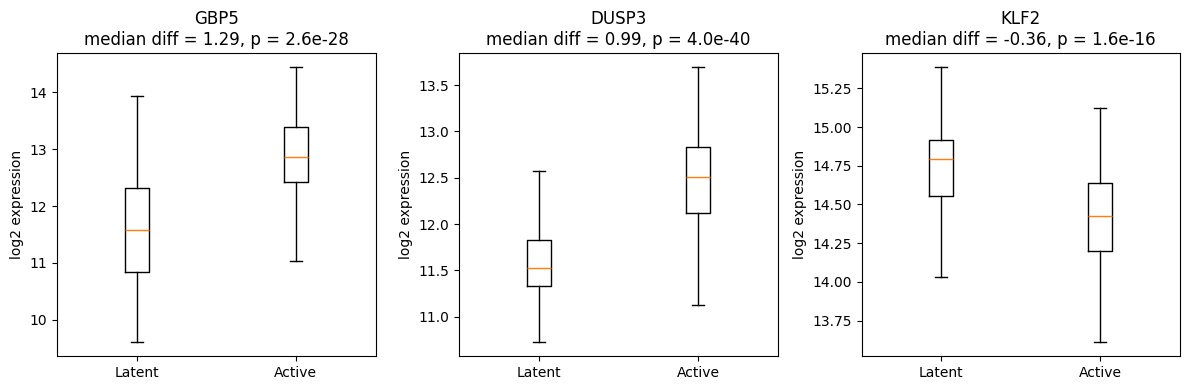

In [21]:
from scipy.stats import mannwhitneyu

active_ids = meta_al.index[meta_al["label"] == 1]
latent_ids = meta_al.index[meta_al["label"] == 0]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, g in zip(axes, ["GBP5", "DUSP3", "KLF2"]):
    a = expr_g.loc[g, active_ids]
    l = expr_g.loc[g, latent_ids]
    p = mannwhitneyu(a, l).pvalue
    ax.boxplot([l, a], showfliers=False)
    ax.set_xticks([1, 2]); ax.set_xticklabels(["Latent", "Active"])
    ax.set_title(f"{g}\nmedian diff = {a.median() - l.median():.2f}, p = {p:.1e}")
    ax.set_ylabel("log2 expression")
plt.tight_layout(); plt.show()

### Biological sanity check
Probes were mapped to gene symbols using the GPL10558 annotation. Probes mapping to more than one gene (3) were dropped, and where several probes mapped to one gene the probe with the highest mean expression was kept, giving a gene-level matrix of 10,065 genes x 362 samples. As a check against known biology, the three Sweeney signature genes behave as expected in active vs latent TB: GBP5 (+1.29 log2, p = 2.6e-28) and DUSP3 (+0.99, p = 4.0e-40) are higher in active TB, and KLF2 (-0.36, p = 1.6e-16) is lower. These p-values are uncorrected and only a sanity check; formal testing with FDR correction is in Stage 5.

# Stage 4: Exploratory Data Analysis

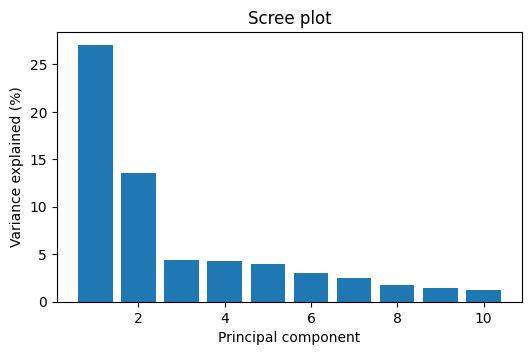

[27.  13.5  4.4  4.3  3.9  3.   2.5  1.8  1.4  1.2]


In [22]:
from sklearn.decomposition import PCA

top = expr_g.var(axis=1).sort_values(ascending=False).index[:2000]
X = expr_g.loc[top].T          # samples x genes

pca = PCA(n_components=10, random_state=42)
pcs = pd.DataFrame(pca.fit_transform(X), index=X.index,
                   columns=[f"PC{i+1}" for i in range(10)])
var = pca.explained_variance_ratio_ * 100

plt.figure(figsize=(6, 3.5))
plt.bar(range(1, 11), var)
plt.xlabel("Principal component"); plt.ylabel("Variance explained (%)")
plt.title("Scree plot"); plt.show()
print(var.round(1))

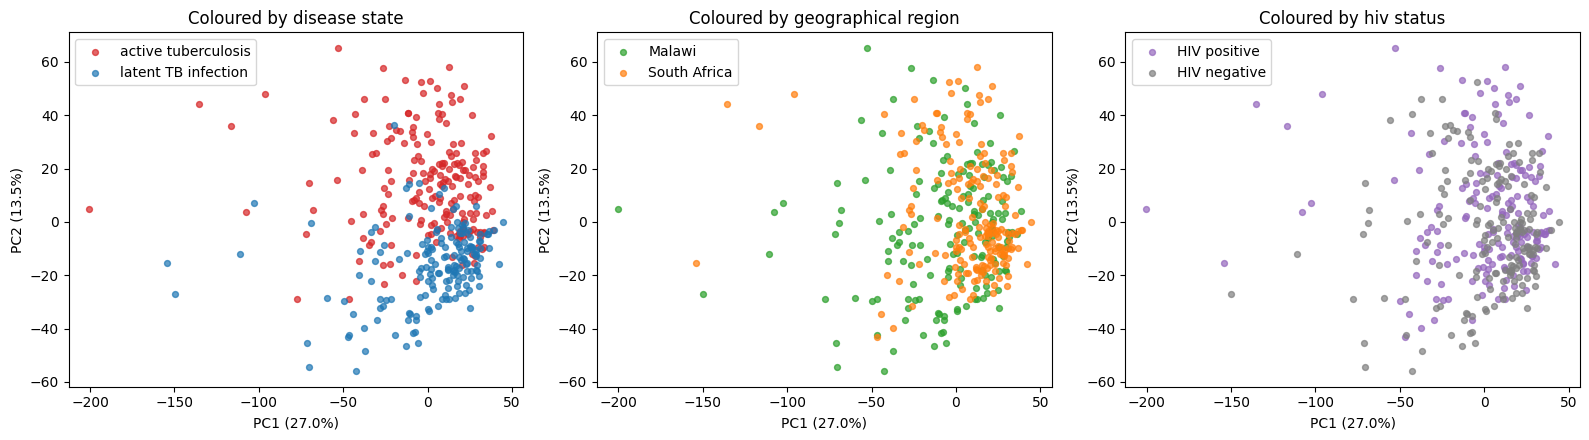

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
panels = [
    ("disease state", {"active tuberculosis": "tab:red", "latent TB infection": "tab:blue"}),
    ("geographical region", {"Malawi": "tab:green", "South Africa": "tab:orange"}),
    ("hiv status", {"HIV positive": "tab:purple", "HIV negative": "tab:gray"}),
]
for ax, (col, cmap) in zip(axes, panels):
    for level, color in cmap.items():
        m = meta_al[col] == level
        ax.scatter(pcs.loc[m, "PC1"], pcs.loc[m, "PC2"], c=color, s=18, alpha=0.7, label=level)
    ax.set_xlabel(f"PC1 ({var[0]:.1f}%)"); ax.set_ylabel(f"PC2 ({var[1]:.1f}%)")
    ax.set_title(f"Coloured by {col}"); ax.legend()
plt.tight_layout(); plt.show()

In [24]:
from scipy.stats import mannwhitneyu

groups = {
    "active vs latent": meta_al["label"] == 1,
    "Malawi vs S. Africa": meta_al["geographical region"] == "Malawi",
    "HIV+ vs HIV-": meta_al["hiv status"] == "HIV positive",
}
rows = []
for pc in pcs.columns[:5]:
    row = {"PC": pc}
    for name, mask in groups.items():
        row[name] = f"{mannwhitneyu(pcs.loc[mask, pc], pcs.loc[~mask, pc]).pvalue:.1e}"
    rows.append(row)
pd.DataFrame(rows).set_index("PC")

,active vs latent,Malawi vs S. Africa,HIV+ vs HIV-
PC,,,
PC1,2.9e-01,8.8e-07,7.9e-01
PC2,1.7e-41,8.0e-02,2.2e-02
PC3,4.5e-02,3.4e-18,3.4e-09
PC4,4.7e-02,8.9e-04,5.2e-08
PC5,2.2e-01,1.5e-01,1.2e-18


In [25]:
out = pcs.index[pcs["PC1"] < -60]
print("Samples with PC1 < -60:", len(out))
print(meta_al.loc[out, ["disease state", "hiv status", "geographical region"]].value_counts())
print()
print("Their median expression vs everyone else:")
print(round(float(expr_g[out].median().median()), 2), "vs", round(float(expr_g.drop(columns=out).median().median()), 2))

Samples with PC1 < -60: 16
disease state        hiv status    geographical region
latent TB infection  HIV negative  Malawi                 5
active tuberculosis  HIV negative  Malawi                 4
                     HIV positive  South Africa           3
                                   Malawi                 2
latent TB infection  HIV positive  Malawi                 1
                                   South Africa           1
Name: count, dtype: int64

Their median expression vs everyone else:
8.71 vs 8.79


### EDA interpretation
PCA was run on the 2,000 most variable genes across the 362 active and latent TB samples. PC1 and PC2 explain 27.0% and 13.5% of the variance, and no later component exceeds 4.4%.

- **Disease:** active and latent TB separate mainly along PC2 (Mann-Whitney p = 1.7e-41), with some overlap, so a classifier should work but not perfectly. PC1 is not associated with disease (p = 0.29).
- **Country:** Malawi and South Africa differ mainly on PC3 (p = 3.4e-18) and weakly on PC1 (p = 8.8e-7). The country effect sits on a different component from the disease effect, but it is still a possible confounder because the disease groups are unevenly split by country (Malawi 102 active vs 71 latent; South Africa 93 vs 96). We therefore evaluate models per country in Stage 7.
- **HIV status:** HIV+ and HIV- differ on PC3 to PC5 (strongest on PC5, p = 1.2e-18), but only weakly on the disease axis PC2 (p = 0.022). HIV changes the blood profile, but this does not by itself show whether it weakens the TB signal; that is tested in Stage 7.

In [26]:
# 1) Which genes drive PC1?
load = pd.Series(pca.components_[0], index=top).sort_values()
print("Most negative PC1 loadings:\n", load.head(10).round(3), "\n")
print("Most positive PC1 loadings:\n", load.tail(10).round(3), "\n")

# 2) Are the outliers poorly correlated with other samples?
corr = expr_g.corr()
mean_corr = corr.mean()
print("Mean correlation with other samples:")
print("  outliers:", round(float(mean_corr[out].mean()), 3))
print("  others:  ", round(float(mean_corr.drop(out).mean()), 3))

Most negative PC1 loadings:
 gene
ARL4A     -0.038
HOXC10    -0.038
TMCC2     -0.036
SLC6A9    -0.036
RAP1GAP   -0.034
BDKRB1    -0.034
ELAVL3    -0.033
CA1       -0.033
ATP8B5P   -0.033
KLC3      -0.033
dtype: float32 

Most positive PC1 loadings:
 gene
FUT8        0.053
LARP1B      0.054
C6orf120    0.054
FAM84B      0.054
SLC39A10    0.055
CREBZF      0.056
CSTF2T      0.056
ENPP4       0.057
VPS50       0.057
ZNF83       0.059
dtype: float32 

Mean correlation with other samples:
  outliers: 0.793
  others:   0.895


**PC1 outliers:** 16 samples (4.4%) lie far from the rest on PC1 (PC1 < -60). They come from every group (9 active TB, 7 latent TB; both HIV statuses; both countries) and have a normal overall expression level (median 8.71 vs 8.79). Their PC1 loadings are spread thinly over many unrelated genes (none above 0.06 in magnitude), and the outliers correlate less with other samples (mean correlation 0.79 vs 0.90). This suggests a broad technical or sample-composition effect, but we could not identify its cause. Because PC1 is unrelated to disease (p = 0.29), we kept all 362 samples in the main analysis and repeat the differential expression without these 16 as a sensitivity check.

In [27]:
outliers = list(out)
print("Outliers flagged:", len(outliers))

for g in ["HBA1", "HBA2", "HBB"]:
    if g in expr_g.index:
        o = expr_g.loc[g, outliers].median()
        r = expr_g.loc[g].drop(outliers).median()
        print(f"{g}: outliers {o:.2f} vs others {r:.2f}")
    else:
        print(g, "not in the filtered gene matrix")

Outliers flagged: 16
HBA1: outliers 15.72 vs others 15.69
HBA2: outliers 15.82 vs others 15.80
HBB: outliers 15.72 vs others 15.71


# Stage 5: Core Analysis: Differential Expression


In [28]:
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

def run_de(expr, meta):
    a = expr.loc[:, meta.index[meta["label"] == 1]]
    l = expr.loc[:, meta.index[meta["label"] == 0]]
    t, p = ttest_ind(a, l, axis=1, equal_var=False)
    res = pd.DataFrame({"log2FC": a.mean(axis=1) - l.mean(axis=1), "t": t, "pval": p}, index=expr.index)
    res["FDR"] = multipletests(res["pval"], method="fdr_bh")[1]
    return res.sort_values("pval")

de = run_de(expr_g, meta_al)

# thresholds: FDR < 0.05 and |log2FC| > 0.5 (about 1.4-fold; a judgement call)
de["sig"] = (de["FDR"] < 0.05) & (de["log2FC"].abs() > 0.5)
print("Genes tested:", len(de))
print("FDR < 0.05:", (de["FDR"] < 0.05).sum())
print("FDR < 0.05 and |log2FC| > 0.5:", de["sig"].sum(),
      "| up in active:", (de["sig"] & (de["log2FC"] > 0)).sum(),
      "| down in active:", (de["sig"] & (de["log2FC"] < 0)).sum())
print()
print(de.head(15).round(4))
print()
print(de.loc[["GBP5", "DUSP3", "KLF2"]].round(4))

Genes tested: 10065
FDR < 0.05: 6873
FDR < 0.05 and |log2FC| > 0.5: 1577 | up in active: 800 | down in active: 777

         log2FC          t  pval  FDR   sig
gene                                       
LHFPL2   1.2995  18.465799   0.0  0.0  True
FCGR1B   2.0528  18.811001   0.0  0.0  True
S100A8   1.1766  16.726299   0.0  0.0  True
ANKRD22  1.9675  17.683201   0.0  0.0  True
FCGR1A   2.3651  19.951300   0.0  0.0  True
SMARCD3  1.2859  17.373899   0.0  0.0  True
AIM2     1.7398  18.096399   0.0  0.0  True
DUSP3    0.8875  18.503500   0.0  0.0  True
VAMP5    1.0604  16.778000   0.0  0.0  True
FLVCR2   0.7911  16.712200   0.0  0.0  True
FCMR    -1.0092 -16.608200   0.0  0.0  True
CASP1    0.8737  16.069099   0.0  0.0  True
TLR5     1.1942  15.736000   0.0  0.0  True
DRAM1    0.9525  15.731200   0.0  0.0  True
GBP6     2.3493  15.866200   0.0  0.0  True

       log2FC        t  pval  FDR    sig
gene                                    
GBP5   1.1944  13.0637   0.0  0.0   True
DUSP3  0.887

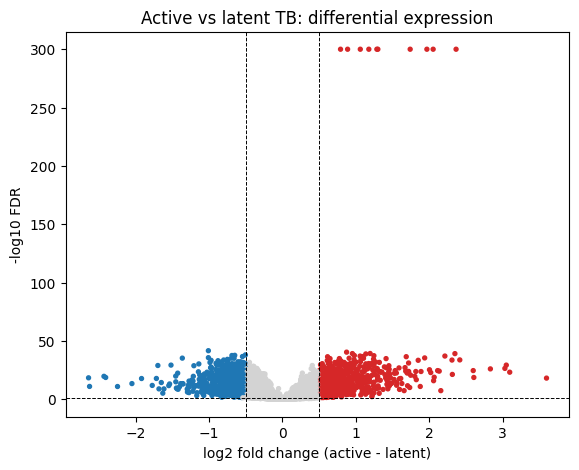

In [29]:
# volcano plot
plt.figure(figsize=(6.5, 5))
colors = np.where(de["sig"] & (de["log2FC"] > 0), "tab:red",
         np.where(de["sig"] & (de["log2FC"] < 0), "tab:blue", "lightgray"))
plt.scatter(de["log2FC"], -np.log10(de["FDR"].clip(lower=1e-300)), c=colors, s=8)
plt.axvline(0.5, ls="--", c="k", lw=0.7); plt.axvline(-0.5, ls="--", c="k", lw=0.7)
plt.axhline(-np.log10(0.05), ls="--", c="k", lw=0.7)
plt.xlabel("log2 fold change (active - latent)"); plt.ylabel("-log10 FDR")
plt.title("Active vs latent TB: differential expression"); plt.show()

In [30]:
pd.set_option("display.float_format", lambda x: f"{x:.3g}")
print(de.head(10)[["log2FC", "pval", "FDR"]])
print(de.loc[["GBP5", "DUSP3", "KLF2"]][["log2FC", "pval", "FDR"]])

de.to_csv("data/de_active_vs_latent.csv")

         log2FC  pval  FDR
gene                      
LHFPL2      1.3     0    0
FCGR1B     2.05     0    0
S100A8     1.18     0    0
ANKRD22    1.97     0    0
FCGR1A     2.37     0    0
SMARCD3    1.29     0    0
AIM2       1.74     0    0
DUSP3     0.887     0    0
VAMP5      1.06     0    0
FLVCR2    0.791     0    0
       log2FC     pval      FDR
gene                           
GBP5     1.19  6.7e-32  6.3e-30
DUSP3   0.887        0        0
KLF2   -0.311 6.19e-18 6.77e-17


In [31]:
keep_ids = meta_al.index.difference(out)
de_no = run_de(expr_g[keep_ids], meta_al.loc[keep_ids])
de_no["sig"] = (de_no["FDR"] < 0.05) & (de_no["log2FC"].abs() > 0.5)

s_all, s_no = set(de.index[de["sig"]]), set(de_no.index[de_no["sig"]])
print("Significant, all 362 samples:", len(s_all))
print("Significant, without 16 outliers (n=346):", len(s_no))
print("Overlap:", len(s_all & s_no), f"({len(s_all & s_no)/len(s_all)*100:.1f}% of the original list)")

Significant, all 362 samples: 1577
Significant, without 16 outliers (n=346): 1549
Overlap: 1498 (95.0% of the original list)


In [32]:
res = {}
for country in ["Malawi", "South Africa"]:
    m = meta_al[meta_al["geographical region"] == country]
    res[country] = run_de(expr_g[m.index], m)
    print(country, "| n =", len(m), "| FDR<0.05 & |log2FC|>0.5:",
          ((res[country]["FDR"] < 0.05) & (res[country]["log2FC"].abs() > 0.5)).sum())

fc = pd.DataFrame({"Malawi": res["Malawi"]["log2FC"], "SA": res["South Africa"]["log2FC"]}).dropna()
print("Correlation of log2FC between countries (all genes):", round(fc["Malawi"].corr(fc["SA"]), 3))

sig_genes = de.index[de["sig"]]
same_dir = (np.sign(fc.loc[sig_genes, "Malawi"]) == np.sign(fc.loc[sig_genes, "SA"])).mean()
print(f"Of the {len(sig_genes)} pooled hits, same direction in both countries: {same_dir*100:.1f}%")

Malawi | n = 173 | FDR<0.05 & |log2FC|>0.5: 1800
South Africa | n = 189 | FDR<0.05 & |log2FC|>0.5: 1721
Correlation of log2FC between countries (all genes): 0.814
Of the 1577 pooled hits, same direction in both countries: 99.9%


### Differential expression results
Welch's t-test was run on each of 10,065 genes (active vs latent TB, n = 195 vs 167), with Benjamini-Hochberg FDR correction. Log2 fold change is the difference in mean log2 expression (active minus latent). We call a gene significant if FDR < 0.05 and |log2FC| > 0.5 (about 1.4-fold, a judgement call to avoid calling tiny effects).

- 6,873 genes had FDR < 0.05; 1,577 also had |log2FC| > 0.5 (800 higher and 777 lower in active TB). The volcano plot is roughly symmetric.
- Among the strongest up-regulated genes are FCGR1A, FCGR1B, GBP6, AIM2, ANKRD22 and S100A8.
- Of the Sweeney signature genes, GBP5 (log2FC +1.19) and DUSP3 (+0.89) are significant hits. KLF2 is significant (FDR < 0.05) but its change (-0.31) is below our fold-change cutoff.

### Robustness checks
- **Without the 16 PC1 outliers (n = 346):** 1,549 genes were significant, and 1,498 (95.0%) of the original 1,577 were still significant. The main result does not depend on these samples.
- **By country:** run separately, Malawi (n = 173) gave 1,800 and South Africa (n = 189) gave 1,721 significant genes. Gene-level log2FC values correlate at 0.81 between countries, and 99.9% of the 1,577 pooled hits change in the same direction in both. The active vs latent signal is therefore consistent across sites. Each country alone gave more hits than the pooled analysis, possibly because between-country differences add noise when samples are pooled; we did not test this.

# Stage 6: Biological Interpretation

In [33]:
!pip install gseapy -q
import gseapy as gp
import time

# gene lists from the Stage 5 results table `de`
background = list(expr_g.index)                           # the 10,065 genes we tested
up_genes = list(de.index[de["sig"] & (de["log2FC"] > 0)])
down_genes = list(de.index[de["sig"] & (de["log2FC"] < 0)])
print("up:", len(up_genes), "| down:", len(down_genes), "| background:", len(background))

# gene-set libraries (with retries)
LIBS = ["MSigDB_Hallmark_2020", "GO_Biological_Process_2023"]
libdict = {}
for lib in LIBS:
    for attempt in range(3):
        try:
            libdict[lib] = gp.get_library(lib)
            print(lib, "downloaded:", len(libdict[lib]), "gene sets")
            break
        except Exception as e:
            print(lib, "attempt", attempt + 1, "failed:", type(e).__name__)
            time.sleep(5)

print("Libraries available:", list(libdict))

up: 800 | down: 777 | background: 10065
MSigDB_Hallmark_2020 downloaded: 50 gene sets
GO_Biological_Process_2023 downloaded: 5406 gene sets
Libraries available: ['MSigDB_Hallmark_2020', 'GO_Biological_Process_2023']


In [34]:
enr = {}
for name, genes in [("up", up_genes), ("down", down_genes)]:
    frames = []
    for lib, gs in libdict.items():
        r = gp.enrich(gene_list=genes, gene_sets=gs, background=background,
                      outdir=None, verbose=False).results
        r["Library"] = lib
        frames.append(r)
    enr[name] = pd.concat(frames, ignore_index=True)

for name in ["up", "down"]:
    for lib in libdict:
        r = enr[name][enr[name]["Library"] == lib].sort_values("Adjusted P-value")
        print(f"\n=== {name.upper()} in active TB | {lib} ===")
        print(r.head(8)[["Term", "Overlap", "Adjusted P-value"]].to_string(index=False))


=== UP in active TB | MSigDB_Hallmark_2020 ===
                             Term Overlap  Adjusted P-value
        Interferon Gamma Response  66/179          1.81e-26
        Interferon Alpha Response   38/89          6.86e-18
            Inflammatory Response  40/135           1.4e-12
    TNF-alpha Signaling via NF-kB  33/143          1.91e-07
                       Complement  30/137          2.36e-06
             IL-2/STAT5 Signaling  30/145          7.16e-06
         IL-6/JAK/STAT3 Signaling   17/59          1.34e-05
Epithelial Mesenchymal Transition   20/84           3.9e-05

=== UP in active TB | GO_Biological_Process_2023 ===
                                                          Term Overlap  Adjusted P-value
                    Defense Response To Bacterium (GO:0042742)   39/96          2.51e-15
                     Defense Response To Symbiont (GO:0140546)  33/111          1.87e-08
                        Defense Response To Virus (GO:0051607)  36/141          1.83e-07
  

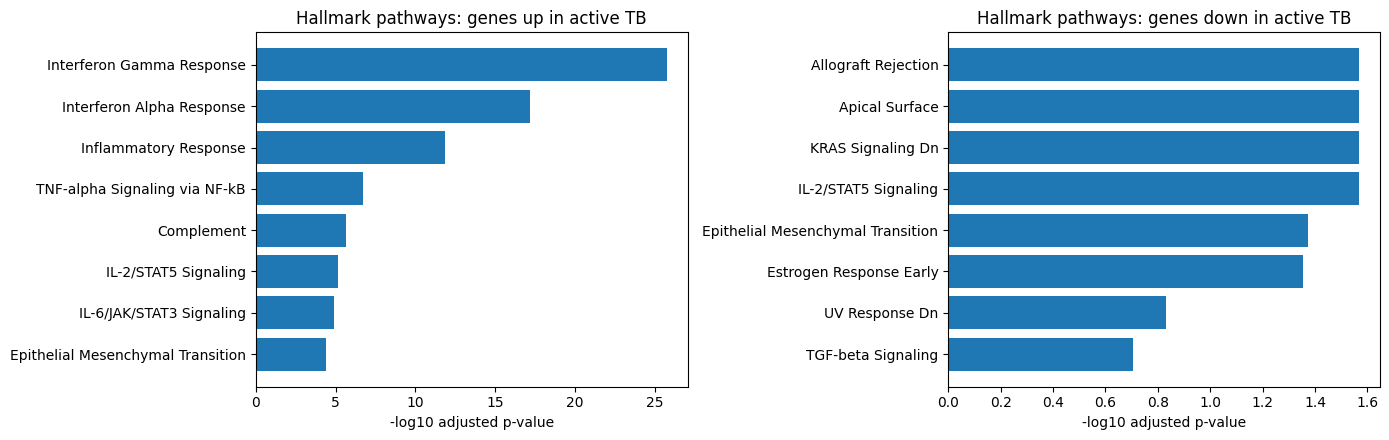

In [35]:
hall = LIBS[0]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, name in zip(axes, ["up", "down"]):
    r = enr[name][enr[name]["Library"] == hall].sort_values("Adjusted P-value").head(8)
    ax.barh(r["Term"][::-1], -np.log10(r["Adjusted P-value"][::-1]))
    ax.set_xlabel("-log10 adjusted p-value")
    ax.set_title(f"Hallmark pathways: genes {name} in active TB")
plt.tight_layout(); plt.show()

### Pathway enrichment
Enrichment of the 800 genes higher and 777 genes lower in active TB was tested against MSigDB Hallmark (2020) and GO Biological Process (2023), using the 10,065 genes tested for differential expression as the background and Benjamini-Hochberg adjusted p-values.

- **Higher in active TB:** the strongest enrichment is Interferon Gamma Response (adjusted p about 1e-26), then Interferon Alpha Response (about 1e-17) and Inflammatory Response (about 1e-12). TNF-alpha/NF-kB, Complement, IL-2/STAT5 and IL-6/JAK/STAT3 signaling are also enriched. This supports the hypothesis that active TB shows an interferon-driven blood signature.
- **Lower in active TB:** enrichment is much weaker (best adjusted p about 0.03), and only a few Hallmark terms pass 0.05 (e.g. Allograft Rejection, Apical Surface, KRAS Signaling Dn, IL-2/STAT5 Signaling). IL-2/STAT5 and Epithelial Mesenchymal Transition also appear in the up-regulated list, so they contain genes changing in both directions. We do not draw biological conclusions from the down-regulated list.

In [36]:
ifn_up = [g for g in up_genes if g in ["GBP1","GBP2","GBP4","GBP5","GBP6","STAT1","IRF1","AIM2","FCGR1A","FCGR1B","ANKRD22","CASP1","TAP1","PSMB9"]]
print(len(ifn_up), "of 14 well-known interferon-related genes are in the up list:", ifn_up)

11 of 14 well-known interferon-related genes are in the up list: ['FCGR1B', 'ANKRD22', 'FCGR1A', 'AIM2', 'CASP1', 'GBP6', 'GBP5', 'GBP2', 'GBP1', 'TAP1', 'GBP4']


In [37]:
for g in ["STAT1", "IRF1", "PSMB9"]:
    if g in de.index:
        print(g, de.loc[g, ["log2FC", "FDR"]].to_dict())
    else:
        print(g, "not in the gene matrix (filtered out or not on the array)")

STAT1 {'log2FC': 0.49585723876953125, 'FDR': 6.109549360540297e-20}
IRF1 {'log2FC': 0.3297309875488281, 'FDR': 3.600758460898574e-13}
PSMB9 {'log2FC': 0.3114900588989258, 'FDR': 1.5785723011025782e-08}


**Interferon-related genes:** of 14 interferon-related genes chosen a priori as examples (GBP1, GBP2, GBP4, GBP5, GBP6, STAT1, IRF1, AIM2, FCGR1A, FCGR1B, ANKRD22, CASP1, TAP1, PSMB9), 11 are among the genes higher in active TB. This list was chosen informally and is illustrative; the enrichment analysis above is the main evidence.

**Link to the research question:** the genes that separate active from latent TB are strongly enriched for interferon (gamma and alpha) and inflammatory pathways, consistent with our hypothesis (Objective 2).

The 3 of the 14 interferon-related genes not in the up list (STAT1, IRF1, PSMB9) are all significantly higher in active TB (FDR < 1e-7) but below the |log2FC| > 0.5 cutoff (log2FC +0.50, +0.33, +0.31).

# Stage 7: Machine Learning

In [38]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score, accuracy_score

X = expr_g.T.loc[meta_al.index]          # samples x genes
y = meta_al["label"].values              # 1 = active, 0 = latent
strata = (meta_al["label"].astype(str) + meta_al["geographical region"] + meta_al["hiv status"]).values

def cv_scores(model, seeds=range(5)):
    aucs, accs, oof0 = [], [], None
    for s in seeds:
        skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=s)
        p = cross_val_predict(model, X, y, cv=list(skf.split(X, strata)),
                              method="predict_proba")[:, 1]
        aucs.append(roc_auc_score(y, p)); accs.append(accuracy_score(y, p > 0.5))
        if oof0 is None: oof0 = p
    return np.mean(aucs), np.std(aucs), np.mean(accs), np.std(accs), oof0

# Baseline 1: majority class
base = DummyClassifier(strategy="most_frequent")
b_auc, b_auc_sd, b_acc, b_acc_sd, _ = cv_scores(base)

# Baseline 2: Sweeney 3-gene score = (GBP5 + DUSP3)/2 - KLF2 (no training needed)
sweeney = (X["GBP5"] + X["DUSP3"]) / 2 - X["KLF2"]
s_auc = roc_auc_score(y, sweeney)

# Main model: top 100 genes (selected inside each fold) + logistic regression
model = Pipeline([
    ("select", SelectKBest(f_classif, k=100)),
    ("scale", StandardScaler()),
    ("clf", LogisticRegression(C=0.1, max_iter=2000)),
])
m_auc, m_auc_sd, m_acc, m_acc_sd, oof = cv_scores(model)

print(f"Majority class : AUC {b_auc:.3f} | accuracy {b_acc:.3f}")
print(f"Sweeney 3-gene : AUC {s_auc:.3f} (no training, formula applied directly)")
print(f"Logistic model : AUC {m_auc:.3f} +/- {m_auc_sd:.3f} | accuracy {m_acc:.3f} +/- {m_acc_sd:.3f}  (5-fold CV x 5 repeats)")

Majority class : AUC 0.500 | accuracy 0.539
Sweeney 3-gene : AUC 0.926 (no training, formula applied directly)
Logistic model : AUC 0.954 +/- 0.002 | accuracy 0.875 +/- 0.007  (5-fold CV x 5 repeats)


In [39]:
from sklearn.metrics import roc_auc_score
rng = np.random.default_rng(0)

def auc_ci(y_true, score, n_boot=1000):
    y_true, score = np.asarray(y_true), np.asarray(score)
    aucs = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y_true), len(y_true))
        if len(set(y_true[i])) < 2:
            continue
        aucs.append(roc_auc_score(y_true[i], score[i]))
    return np.percentile(aucs, [2.5, 97.5])

scores = {"Logistic model": oof, "Sweeney score": sweeney.values}
rows = []
groupings = {
    "HIV status": meta_al["hiv status"],
    "Country": meta_al["geographical region"],
    "HIV x Country": meta_al["hiv status"] + " | " + meta_al["geographical region"],
}
for gname, g in groupings.items():
    for level in sorted(g.unique()):
        m = (g == level).values
        for sname, s in scores.items():
            lo, hi = auc_ci(y[m], s[m])
            rows.append({"Grouping": gname, "Subgroup": level, "Model": sname, "n": m.sum(),
                         "AUC": round(roc_auc_score(y[m], s[m]), 3),
                         "95% CI": f"{lo:.3f} to {hi:.3f}"})
pd.DataFrame(rows)

,Grouping,Subgroup,Model,n,AUC,95% CI
0,HIV status,HIV negative,Logistic model,180,0.984,0.969 to 0.993
1,HIV status,HIV negative,Sweeney score,180,0.967,0.940 to 0.987
2,HIV status,HIV positive,Logistic model,182,0.922,0.881 to 0.956
3,HIV status,HIV positive,Sweeney score,182,0.889,0.834 to 0.934
4,Country,Malawi,Logistic model,173,0.96,0.931 to 0.984
5,Country,Malawi,Sweeney score,173,0.901,0.854 to 0.941
6,Country,South Africa,Logistic model,189,0.944,0.911 to 0.972
7,Country,South Africa,Sweeney score,189,0.942,0.906 to 0.972
8,HIV x Country,HIV negative | Malawi,Logistic model,86,0.992,0.976 to 1.000
9,HIV x Country,HIV negative | Malawi,Sweeney score,86,0.955,0.912 to 0.988


In [40]:
def transfer(train_c, test_c):
    tr = (meta_al["geographical region"] == train_c).values
    te = (meta_al["geographical region"] == test_c).values
    model.fit(X[tr], y[tr])
    p = model.predict_proba(X[te])[:, 1]
    lo, hi = auc_ci(y[te], p)
    print(f"Train {train_c} (n={tr.sum()}) -> test {test_c} (n={te.sum()}): "
          f"AUC {roc_auc_score(y[te], p):.3f} (95% CI {lo:.3f} to {hi:.3f})")

transfer("Malawi", "South Africa")
transfer("South Africa", "Malawi")

Train Malawi (n=173) -> test South Africa (n=189): AUC 0.915 (95% CI 0.873 to 0.953)
Train South Africa (n=189) -> test Malawi (n=173): AUC 0.926 (95% CI 0.884 to 0.958)


### Model and baselines
Task: classify active TB (n = 195) vs latent TB (n = 167) from gene-level expression (10,065 genes). The main model selects the top 100 genes by ANOVA F-score and fits an L2-regularised logistic regression (C = 0.1); gene selection is done inside each cross-validation fold to avoid leakage. We used 5-fold stratified cross-validation (stratified by disease, country and HIV status), repeated 5 times with different random splits. The Sweeney score is (GBP5 + DUSP3)/2 - KLF2, applied directly with no training.

| Model | AUC | Accuracy |
|---|---|---|
| Majority class | 0.500 | 0.539 |
| Sweeney 3-gene score | 0.926 | not computed |
| Logistic regression (100 genes) | 0.954 | 0.875 |

The model clearly beats the majority-class baseline and slightly exceeds the Sweeney score. The Sweeney score was developed partly on data that likely include GSE37250, so its performance here is probably optimistic.

AUC difference, HIV- minus HIV+: 0.062 (95% CI 0.024 to 0.105)


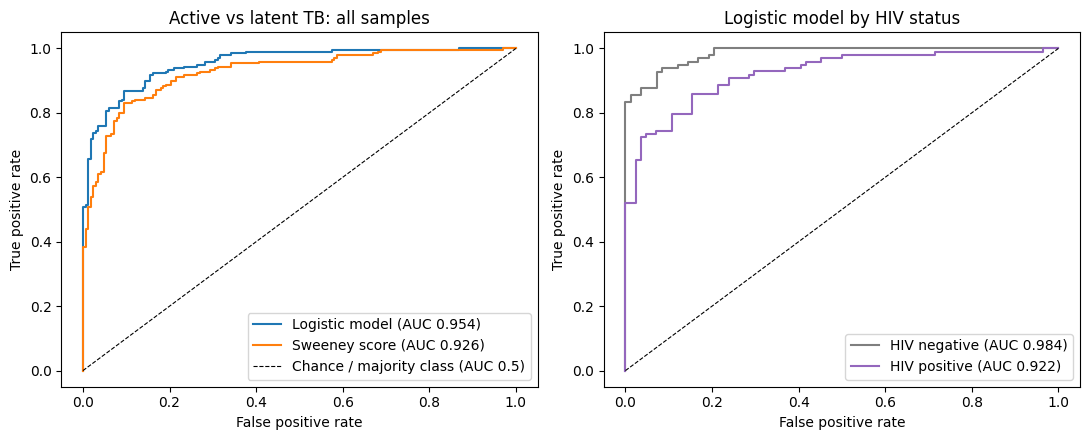

In [41]:
from sklearn.metrics import roc_curve

# 1) bootstrap CI for the AUC difference (HIV- minus HIV+)
hiv_neg = (meta_al["hiv status"] == "HIV negative").values
diffs = []
for _ in range(2000):
    i = rng.integers(0, len(y), len(y))
    yi, pi, ni = y[i], oof[i], hiv_neg[i]
    if len(set(yi[ni])) < 2 or len(set(yi[~ni])) < 2:
        continue
    diffs.append(roc_auc_score(yi[ni], pi[ni]) - roc_auc_score(yi[~ni], pi[~ni]))
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f"AUC difference, HIV- minus HIV+: {np.mean(diffs):.3f} (95% CI {lo:.3f} to {hi:.3f})")

# 2) ROC curves
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for name, s in scores.items():
    fpr, tpr, _ = roc_curve(y, s)
    ax[0].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y, s):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=0.8, label="Chance / majority class (AUC 0.5)")
ax[0].set_title("Active vs latent TB: all samples"); ax[0].legend(loc="lower right")

for level, c in [("HIV negative", "tab:gray"), ("HIV positive", "tab:purple")]:
    m = (meta_al["hiv status"] == level).values
    fpr, tpr, _ = roc_curve(y[m], oof[m])
    ax[1].plot(fpr, tpr, c=c, label=f"{level} (AUC {roc_auc_score(y[m], oof[m]):.3f})")
ax[1].plot([0, 1], [0, 1], "k--", lw=0.8)
ax[1].set_title("Logistic model by HIV status"); ax[1].legend(loc="lower right")
for a in ax:
    a.set_xlabel("False positive rate"); a.set_ylabel("True positive rate")
plt.tight_layout(); plt.show()

### Performance by HIV status and country
AUCs are computed from out-of-fold predictions, with 95% bootstrap confidence intervals (1,000 resamples of the samples).

| Subgroup | n | Logistic model AUC (95% CI) | Sweeney AUC (95% CI) |
|---|---|---|---|
| HIV negative | 180 | 0.984 (0.969 to 0.993) | 0.967 (0.940 to 0.987) |
| HIV positive | 182 | 0.922 (0.881 to 0.956) | 0.889 (0.834 to 0.934) |
| Malawi | 173 | 0.960 (0.931 to 0.984) | 0.901 (0.854 to 0.941) |
| South Africa | 189 | 0.944 (0.911 to 0.972) | 0.942 (0.906 to 0.972) |

- **HIV status:** the model discriminates active from latent TB less well in HIV-positive patients (AUC 0.922) than in HIV-negative patients (0.984), and the intervals do not overlap. The drop is about 0.06, so performance remains high. The same direction appears within each country (Malawi 0.944 vs 0.992; South Africa 0.901 vs 0.980), though subgroups of about 90 samples have wide intervals.
- **Country:** the two countries give similar AUCs. Training on one country and testing on the other gives AUC 0.915 (Malawi to South Africa) and 0.926 (South Africa to Malawi), a small drop from within-country performance, so the model is not simply learning country.
- **Versus Sweeney:** the model is higher in most subgroups but the intervals mostly overlap, so we describe it as matching or modestly improving on the 3-gene score.
- **Caveats:** the confidence intervals reflect sample variability only, not model retraining, and the Sweeney score was likely developed partly on this dataset.

**Direct test of the HIV effect:** the difference in AUC between HIV-negative and HIV-positive patients is 0.062 (95% bootstrap CI 0.024 to 0.105), so the interval excludes zero and the model is significantly less accurate in HIV-positive patients. The ROC curves show the gap is largest at low false-positive rates. This supports the second part of our hypothesis, although performance in HIV-positive patients remains high (AUC 0.922).

# Stage 8: Conclusions and Limitations

## Answer to the research question
Whole-blood gene expression separates active from latent TB well in African adults (cross-validated AUC 0.954 across 362 samples), and it still works in people living with HIV, although less well (AUC 0.922 vs 0.984 in HIV-negative patients).

## Objectives
1. **Differential expression:** 1,577 of 10,065 genes differ between active and latent TB (FDR < 0.05, |log2FC| > 0.5): 800 higher and 777 lower in active TB. The result is robust to removing 16 PC1 outliers (95% of hits retained) and is consistent across Malawi and South Africa (99.9% of hits change in the same direction in both).
2. **Enrichment:** genes higher in active TB are most strongly enriched for Interferon Gamma Response (adjusted p about 1e-26) and Interferon Alpha Response (about 1e-17), followed by inflammatory response, supporting an interferon-driven signature. Genes lower in active TB show only weak enrichment, which we do not interpret.
3. **Classifier vs baselines:** a 100-gene logistic regression reached AUC 0.954 and accuracy 0.875, against 0.500 and 0.539 for the majority-class baseline and AUC 0.926 for the 3-gene Sweeney score. The improvement over Sweeney is modest.
4. **HIV status:** AUC was 0.062 lower in HIV-positive patients (95% CI 0.024 to 0.105), supporting the hypothesis that HIV co-infection blurs the signal. The model remains useful in HIV-positive patients.

## Limitations
- **No external validation.** All performance numbers come from cross-validation within one dataset (GSE37250), so they are likely optimistic for new cohorts.
- **Sweeney baseline is likely optimistic**, since the score was probably developed partly on data that include this dataset.
- **Confidence intervals** reflect sample variability only, not variability from retraining the model.
- **Pooled differential expression** ignores country and HIV status as covariates, and the thresholds (FDR 0.05, |log2FC| > 0.5, probe filter) are judgement calls, although the probe filter was not sensitive to the cutoff.
- **Unexplained outliers:** 16 samples were extreme on PC1 for a reason we could not identify.
- **Fixed hyperparameters:** we used 100 genes and C = 0.1 without tuning.
- **Subgroup sizes** of about 90 samples (HIV x country) give wide intervals.
- Only two African countries and adults are covered, with microarray data, so results may not generalise to children or other populations.

## Future work
- Validate on an independent dataset (e.g. GSE19491, or the paediatric cohort including Kenya in GSE39941).
- Adjust differential expression for country and HIV status (e.g. a linear model with covariates).
- Tune the model inside nested cross-validation and test smaller gene signatures.
- Train HIV-specific models and examine why performance drops in HIV-positive patients.